# AI Screenshot & Visual Organizer - Model Training (ML Pipeline)

## 1. Proje Amacı ve Problem Tanımı / Project Purpose & Problem Definition

<details>
<summary><b>🇹🇷 Türkçe Açıklama İçin Tıklayın</b></summary>

Bu çalışmanın amacı, dijital arşivlerde veya e-ticaret platformlarında yüklenen görsellerin (ve ekran görüntülerinin) manuel olarak sınıflandırılması yükünü ortadan kaldırmak için derin öğrenme tabanlı bir otomatik sınıflandırma modeli geliştirmektir. Sistem, görselin içeriğini analiz ederek önceden belirlenmiş e-ticaret kategorilerine (Elektronik, Giyim, Ev & Yaşam vb.) ayırır.

</details>

<details>
<summary><b>🇬🇧 Click for English Description</b></summary>

The purpose of this study is to develop an automated deep learning-based image classification model to eliminate the burden of manual categorization of uploaded images (and screenshots) in digital archives or e-commerce platforms. The system analyzes visual content and sorts them into predefined e-commerce categories (Electronics, Clothing, Home & Living, etc.).

</details>

In [ ]:
import os
import random
from pathlib import Path
from PIL import Image
from tqdm import tqdm
import kagglehub

print("Downloading dataset from Kaggle...")
dataset_path = kagglehub.dataset_download("fatihkgg/ecommerce-product-images-18k")
DATA_DIR = Path(dataset_path)

# Locate training directory
train_dir = next((p for p in DATA_DIR.rglob("*") if p.is_dir() and p.name == "train"), DATA_DIR)
classes = [d.name for d in train_dir.iterdir() if d.is_dir()]

# Create balanced subset to optimize training time
MAX_PER_CLASS = 500
PROCESSED_DATA_DIR = Path("/content/ecommerce_subset")

for cls in classes:
    (PROCESSED_DATA_DIR / cls).mkdir(parents=True, exist_ok=True)

class_counts = {}
for cls in classes:
    src_class_dir = train_dir / cls
    images = list(src_class_dir.glob("*.*"))
    random.shuffle(images)
    selected_images = images[:MAX_PER_CLASS]
    class_counts[cls] = len(selected_images)

    dest_class_dir = PROCESSED_DATA_DIR / cls
    for idx, img_path in enumerate(tqdm(selected_images, desc=f"Processing {cls}")):
        try:
            with Image.open(img_path) as img:
                img = img.convert("RGB").resize((224, 224))
                img.save(dest_class_dir / f"{cls}_{idx:04d}.jpg", quality=85)
        except Exception:
            pass

print("\nDataset Subset Distribution:", class_counts)

100%|██████████| 142M/142M [00:01<00:00, 81.6MB/s]

Extracting files...



Processing BABY_PRODUCTS: 100%|██████████| 500/500 [00:00<00:00, 907.55it/s]


Dataset Subset Distribution: {'BEAUTY_HEALTH': 500, 'ELECTRONICS': 500, 'HOME_KITCHEN_TOOLS': 500, 'CLOTHING_ACCESSORIES_JEWELLERY': 500, 'HOBBY_ARTS_STATIONERY': 500, 'PET_SUPPLIES': 500, 'GROCERY': 500, 'SPORTS_OUTDOOR': 500, 'BABY_PRODUCTS': 500}


## 2. Veri Keşfi (EDA) ve Veri Ön İşleme / Exploratory Data Analysis & Preprocessing

<details>
<summary><b>🇹🇷 Türkçe Açıklama İçin Tıklayın</b></summary>

- **Veri Kaynağı:** Kaggle `ecommerce-product-images-18k` veri seti kullanılmıştır.
- **Optimizasyon:** Eğitim süresini optimize etmek ve dengeli bir dağılım sağlamak amacıyla her sınıftan rastgele 500 örnek seçilerek bir alt küme (`ecommerce_subset`) oluşturulmuştur (Toplam: 4,500 görsel).
- **Ön İşleme:** Tüm görseller RGB formatına dönüştürülmüş, CNN standart boyutu olan `224x224` piksele yeniden boyutlandırılmış ve normalize edilmiştir. Aşırı öğrenmeyi (overfitting) önlemek için eğitim kümesine veri artırma (Data Augmentation: yatay çevirme, açı ve renk oynamaları) uygulanmıştır.

</details>

<details>
<summary><b>🇬🇧 Click for English Description</b></summary>

- **Data Source:** Kaggle `ecommerce-product-images-18k` dataset is used.
- **Optimization:** To optimize training time and ensure balanced distribution, a subset is created by randomly selecting 500 samples per class (`ecommerce_subset`, Total: 4,500 images).
- **Preprocessing:** All images are converted to RGB, resized to the CNN standard size of `224x224` pixels, and normalized. Data augmentation (horizontal flip, rotation, color jitter) is applied to the training set to prevent overfitting.

</details>

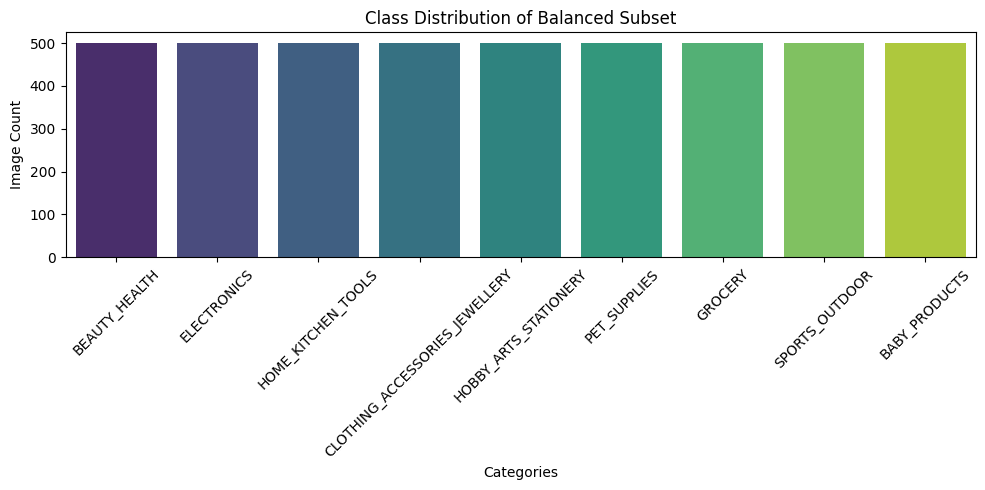

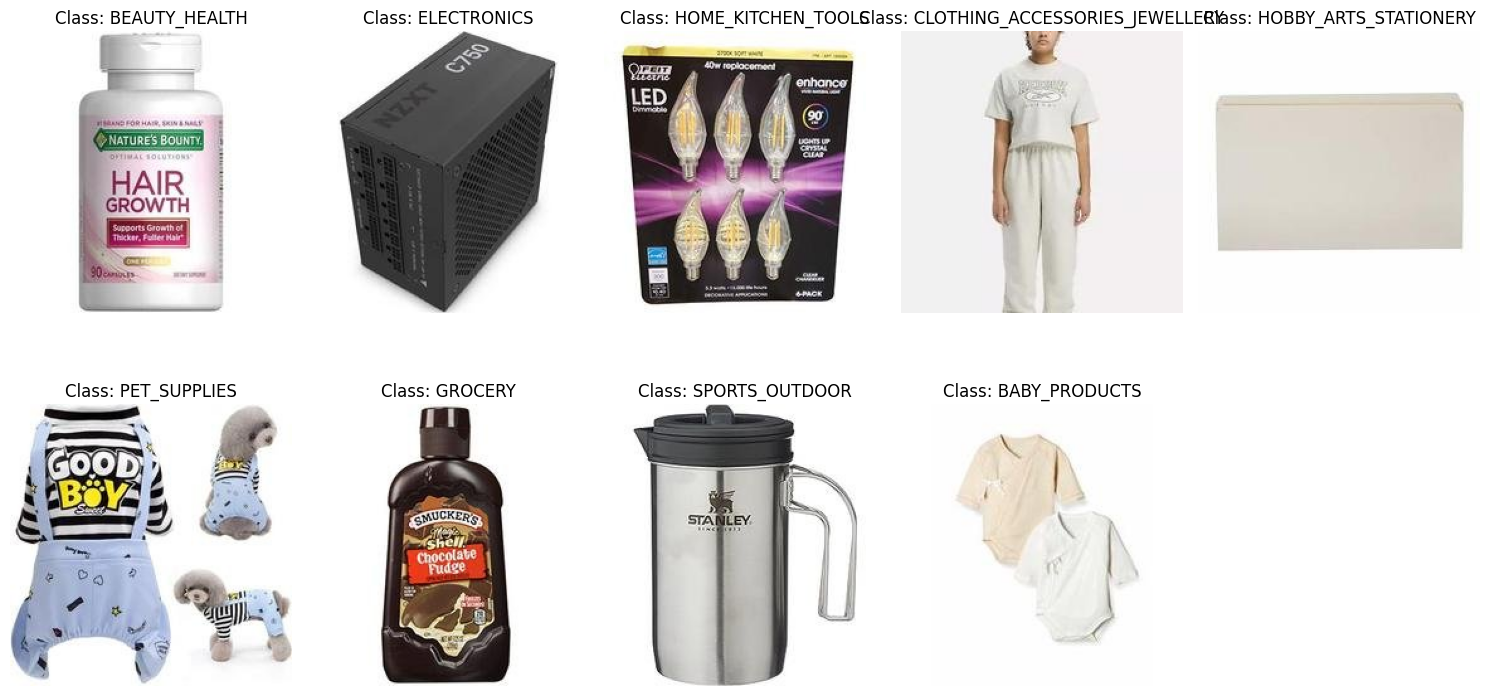

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Class Distribution Bar Plot
plt.figure(figsize=(10, 5))
sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()), hue=list(class_counts.keys()), palette="viridis", legend=False)
plt.title("Class Distribution of Balanced Subset")
plt.xlabel("Categories")
plt.ylabel("Image Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2. Sample Images Grid Visualization
fig, axes = plt.subplots(2, (len(classes) + 1) // 2, figsize=(15, 8))
axes = axes.flatten()
for i, cls in enumerate(classes):
    sample_img_path = random.choice(list((PROCESSED_DATA_DIR / cls).glob("*.jpg")))
    axes[i].imshow(Image.open(sample_img_path))
    axes[i].set_title(f"Class: {cls}")
    axes[i].axis("off")
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

## 3. Model Seçimi, Eğitimi ve Değerlendirme / Model Selection, Training & Evaluation

<details>
<summary><b>🇹🇷 Türkçe Açıklama İçin Tıklayın</b></summary>

- **Mimari:** Sıfırdan bir CNN eğitmek yerine, ImageNet üzerinde önceden eğitilmiş **MobileNetV2** mimarisi kullanılarak Transfer Learning (Feature Extraction) uygulanmıştır. Ön katmanlar dondurulmuş, son sınıflandırma katmanı (classifier) 9 sınıfımıza uyarlanmıştır.
- **Eğitim:** Model, 5 epoch boyunca Adam optimizer ve CrossEntropyLoss kullanılarak eğitilmiştir.
- **Değerlendirme:** Model başarısı Accuracy, Precision, Recall, F1-Score ve Confusion Matrix (Hata Matrisi) metrikleri ile değerlendirilmiştir.

</details>

<details>
<summary><b>🇬🇧 Click for English Description</b></summary>

- **Architecture:** Instead of training a CNN from scratch, Transfer Learning (Feature Extraction) is applied using the **MobileNetV2** architecture pretrained on ImageNet. Early layers are frozen, and the final classifier layer is adapted to our 9 classes.
- **Training:** The model is trained for 5 epochs using the Adam optimizer and CrossEntropyLoss.
- **Evaluation:** Model performance is evaluated using Accuracy, Precision, Recall, F1-Score, and Confusion Matrix metrics.

</details>

In [ ]:
import torch
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active Device: {device}")

# Data Augmentation & Preprocessing Pipelines
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(10),
        transforms.ColorJitter(brightness=0.2, contrast=0.2),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

# Load Dataset & Train/Val Split (80/20)
full_dataset = datasets.ImageFolder(PROCESSED_DATA_DIR, transform=data_transforms['train'])
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

# Apply val transforms to validation subset
val_dataset.dataset.transform = data_transforms['val']

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

class_names = full_dataset.classes
print(f"Total Classes: {len(class_names)} -> {class_names}")
print(f"Train Samples: {len(train_dataset)} | Validation Samples: {len(val_dataset)}")

Active Device: cpu
Total Classes: 9 -> ['BABY_PRODUCTS', 'BEAUTY_HEALTH', 'CLOTHING_ACCESSORIES_JEWELLERY', 'ELECTRONICS', 'GROCERY', 'HOBBY_ARTS_STATIONERY', 'HOME_KITCHEN_TOOLS', 'PET_SUPPLIES', 'SPORTS_OUTDOOR']
Train Samples: 3600 | Validation Samples: 900


In [ ]:
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# Load Pretrained MobileNetV2 (Feature Extraction approach)
model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

for param in model.parameters():
    param.requires_grad = False

# Modify classifier head for our dataset classes
model.classifier[1] = nn.Linear(model.last_channel, len(class_names))
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.classifier.parameters(), lr=0.001)

print("Model architecture is successfully built and ready for training.")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 64.5MB/s]


Model architecture is successfully built and ready for training.


In [ ]:
import time

num_epochs = 5

for epoch in range(num_epochs):
    start_time = time.time()

    # Training Phase
    model.train()
    running_loss, running_corrects = 0.0, 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data)

    train_loss = running_loss / len(train_dataset)
    train_acc = running_corrects.double() / len(train_dataset)

    # Validation Phase
    model.eval()
    val_loss, val_corrects = 0.0, 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * inputs.size(0)
            val_corrects += torch.sum(preds == labels.data)

    v_loss = val_loss / len(val_dataset)
    v_acc = val_corrects.double() / len(val_dataset)

    print(f"Epoch [{epoch+1}/{num_epochs}] ({time.time()-start_time:.1f}s) | "
          f"Train Loss: {train_loss:.4f} - Acc: {train_acc:.4f} | "
          f"Val Loss: {v_loss:.4f} - Acc: {v_acc:.4f}")

print("Training process finished.")

Epoch [1/5] (424.8s) | Train Loss: 1.7474 - Acc: 0.4219 | Val Loss: 1.4942 - Acc: 0.4978
Epoch [2/5] (357.6s) | Train Loss: 1.3884 - Acc: 0.5503 | Val Loss: 1.3532 - Acc: 0.5478
Epoch [3/5] (348.4s) | Train Loss: 1.2451 - Acc: 0.5842 | Val Loss: 1.2749 - Acc: 0.5778
Epoch [4/5] (359.8s) | Train Loss: 1.1720 - Acc: 0.6131 | Val Loss: 1.2586 - Acc: 0.5889
Epoch [5/5] (351.8s) | Train Loss: 1.0969 - Acc: 0.6433 | Val Loss: 1.2194 - Acc: 0.5956
Training process finished.



--- Classification Report ---
                                precision    recall  f1-score   support

                 BABY_PRODUCTS       0.61      0.68      0.65        92
                 BEAUTY_HEALTH       0.58      0.51      0.54        97
CLOTHING_ACCESSORIES_JEWELLERY       0.75      0.73      0.74       105
                   ELECTRONICS       0.52      0.75      0.62       101
                       GROCERY       0.60      0.74      0.66       111
         HOBBY_ARTS_STATIONERY       0.54      0.54      0.54        95
            HOME_KITCHEN_TOOLS       0.64      0.31      0.42       110
                  PET_SUPPLIES       0.65      0.57      0.61        87
                SPORTS_OUTDOOR       0.52      0.53      0.52       102

                      accuracy                           0.60       900
                     macro avg       0.60      0.60      0.59       900
                  weighted avg       0.60      0.60      0.59       900



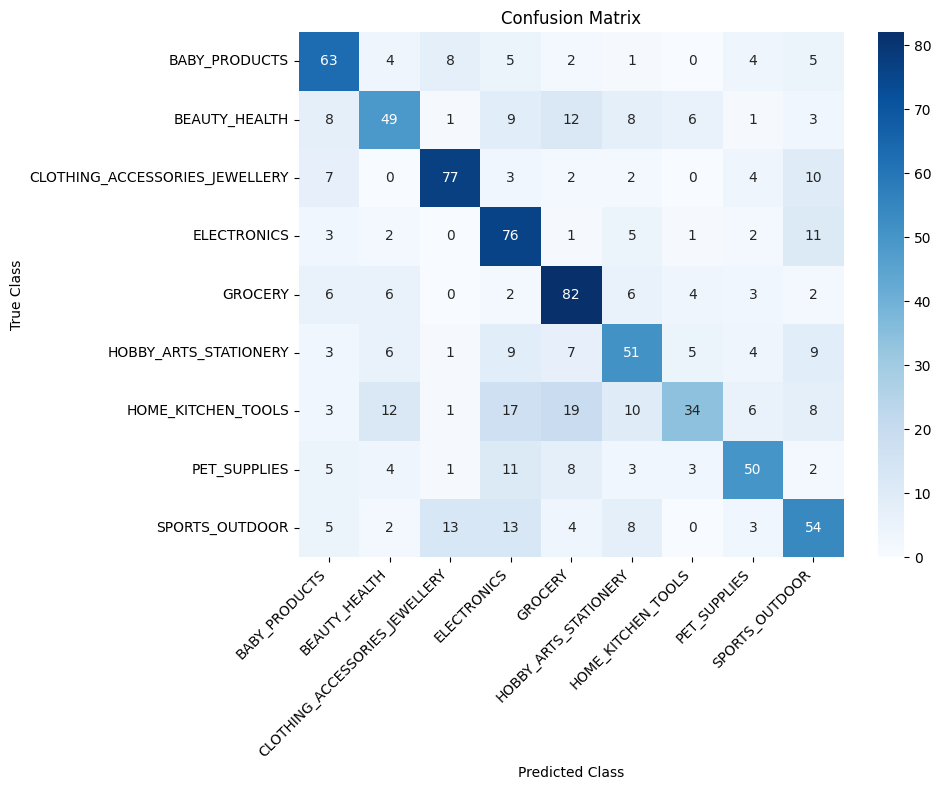

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for inputs, labels in val_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print("\n--- Classification Report ---")
print(classification_report(all_labels, all_preds, target_names=class_names))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
import torch
from google.colab import files

model_save_path = "saved_model.pth"
torch.save({
    'model_state_dict': model.state_dict(),
    'classes': class_names
}, model_save_path)

files.download(model_save_path)
print(f"Model successfully saved and download initiated: {model_save_path}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model successfully saved and download initiated: saved_model.pth


## 4. Çıkarım ve İş Mantığı (Taxonomy Mapping) / Inference & Business Logic

<details>
<summary><b>🇹🇷 Türkçe Açıklama İçin Tıklayın</b></summary>

- **Problem:** Eğittiğimiz model e-ticaret veri setinin ham ve detaylı sınıflarını (`BABY_PRODUCTS`, `ELECTRONICS` vb.) üretmektedir. Ancak kullanıcı deneyimi ve kişisel ekran görüntüsü/galeri organizasyonu için bu ham çıktıların daha genel ve anlamlı üst kategori klasörlerine (`Shopping & Products`, `Tech & Electronics` vb.) dönüştürülmesi gerekir.
- **Çözüm (Business Logic):** Modelin ham tahminini yakalayan ve bunu bir eşleme sözlüğünden (`TAXONOMY_MAP`) geçirerek kullanıcının göreceği nihai klasöre map eden (haritalandıran) bir çıkarım ve iş mantığı katmanı tasarlanmıştır.

</details>

<details>
<summary><b>🇬🇧 Click for English Description</b></summary>

- **Problem:** The trained model produces raw and granular classes from the e-commerce dataset (`BABY_PRODUCTS`, `ELECTRONICS`, etc.). However, for user experience and personal gallery organization, these raw outputs need to be mapped into broader, meaningful high-level folder categories (`Shopping & Products`, `Tech & Electronics`, etc.).
- **Solution (Business Logic):** An inference and business logic layer is designed to capture the raw model prediction and pass it through a mapping dictionary (`TAXONOMY_MAP`) to convert it into the final folder seen by the user.

</details>

Testing random image from class 'SPORTS_OUTDOOR':


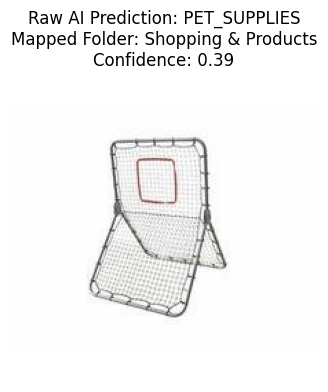

In [ ]:
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
import random
import matplotlib.pyplot as plt

# Taxonomy Mapping Dictionary (Granular E-commerce -> High-Level User Folder)
TAXONOMY_MAP = {
    "BABY_PRODUCTS": "Shopping & Products",
    "CLOTHING_ACCESSORIES_JEWELLERY": "Shopping & Products",
    "BEAUTY_HEALTH": "Shopping & Products",
    "GROCERY": "Shopping & Products",
    "PET_SUPPLIES": "Shopping & Products",
    "SPORTS_OUTDOOR": "Shopping & Products",
    "HOME_KITCHEN_TOOLS": "Home & Living",
    "ELECTRONICS": "Tech & Electronics",
    "HOBBY_ARTS_STATIONERY": "Work & Stationery"
}

# Load Saved Model for Inference
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint = torch.load("saved_model.pth", map_location=device)
loaded_classes = checkpoint['classes']

inference_model = models.mobilenet_v2(weights=None)
inference_model.classifier[1] = nn.Linear(inference_model.last_channel, len(loaded_classes))
inference_model.load_state_dict(checkpoint['model_state_dict'])
inference_model.to(device)
inference_model.eval()

infer_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Inference & Mapping Function
def test_image_prediction(image_path):
    image = Image.open(image_path).convert("RGB")
    tensor = infer_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = inference_model(tensor)
        probabilities = torch.nn.functional.softmax(outputs[0], dim=0)
        confidence, predicted_idx = torch.max(probabilities, 0)

    raw_pred = loaded_classes[predicted_idx.item()]
    conf_score = confidence.item()

    # Apply Taxonomy Mapping
    mapped_folder = TAXONOMY_MAP.get(raw_pred, "General / Archive")

    # Visualization
    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"Raw AI Prediction: {raw_pred}\nMapped Folder: {mapped_folder}\nConfidence: {conf_score:.2f}")
    plt.show()

# Run a Quick Test on a Random Image
random_class = random.choice(classes)
sample_images = list((PROCESSED_DATA_DIR / random_class).glob("*.jpg"))
if sample_images:
    test_image_path = random.choice(sample_images)
    print(f"Testing random image from class '{random_class}':")
    test_image_prediction(test_image_path)
else:
    print("No sample images found for testing.")